# Chapter 10. Dimensionality Reduction
## CPE 490 590
## Rahul Bhadani

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from statistics import mean
plt.rcParams['font.family'] = 'Serif'
plt.rcParams['font.size'] = 15

# 1. Toy Example

In [49]:
toydata = np.array([  
  [1, 1],
  [2, 1],
  [3, 2],
  [-1, -1],
  [-2, -1],
  [-3, -2]  
])

(-5.0, 5.0)

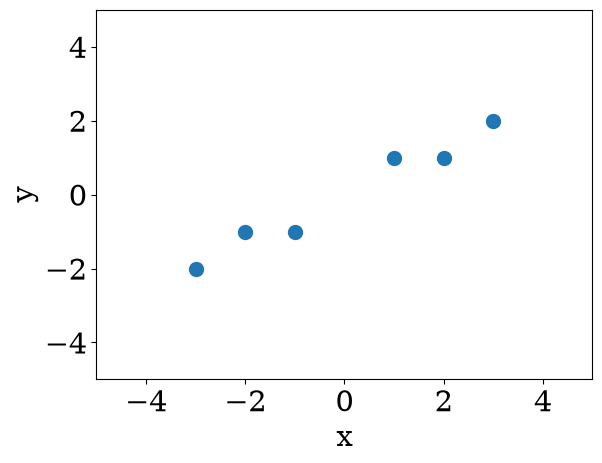

In [50]:
plt.scatter(toydata[:,0], toydata[:,1], s= 100)

# Set the labels for the x and y axes
plt.xlabel('x')
plt.ylabel('y')
plt.xlim([-5, 5])
plt.ylim([-5, 5])

## Apply PCA with one component only


In [51]:
pca_1 = PCA(n_components=1)
pca_1.fit(toydata)
pca_1.explained_variance_ratio_

array([0.99244289])

# Visualize

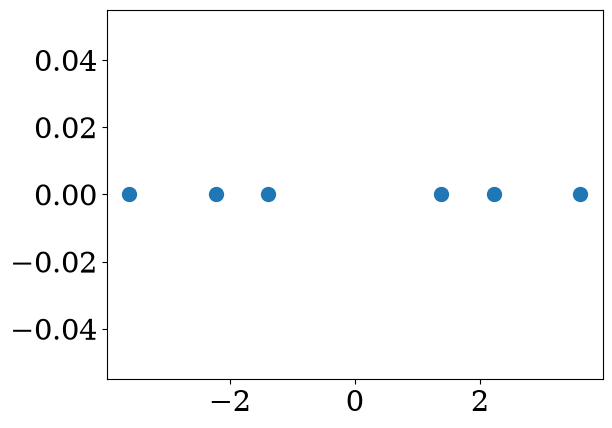

In [52]:
x_trans_1 = pca_1.transform(toydata)
x_trans_1
plt.scatter(x_trans_1, [0]*len(x_trans_1), s= 100)



# What would happen with two PC?

In [53]:
pca_2 = PCA(n_components=2)
pca_2.fit(toydata)
pca_2.explained_variance_ratio_

array([0.99244289, 0.00755711])

In [54]:
pca_2.explained_variance_ratio_[0]+ pca_2.explained_variance_ratio_[1]

np.float64(1.0)

(-5.0, 5.0)

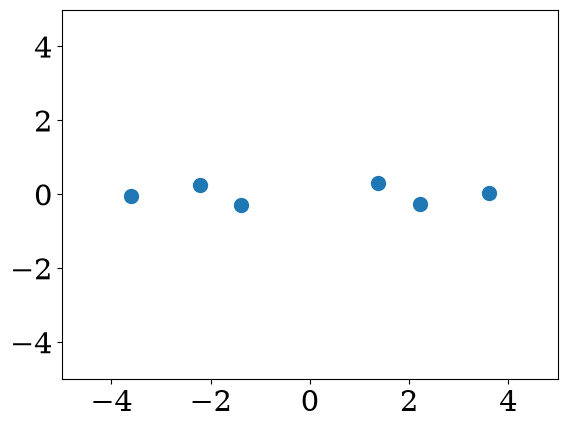

In [55]:
x_trans_2 = pca_2.transform(toydata)
plt.scatter(x_trans_2[:,0], x_trans_2[:,1], s= 100)
plt.xlim([-5, 5])
plt.ylim([-5, 5])

## What's the relationship with original plot?

# 2. PCA using SVD on Iris Data

In [56]:
import polars as pl
import torch
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Serif'
plt.rcParams['font.size'] = 21


# Load the Iris dataset
Iris = pl.read_csv("https://raw.githubusercontent.com/rahulbhadani/Datasets/refs/heads/master/Iris/iris.data")
Iris.head()
Iris = Iris.drop_nulls()

In [57]:
Iris

SepalLength,SepalWidth,PetalLength,PetalWidth,Class
f64,f64,f64,f64,str
5.1,3.5,1.4,0.2,"""Iris-setosa"""
4.9,3.0,1.4,0.2,"""Iris-setosa"""
4.7,3.2,1.3,0.2,"""Iris-setosa"""
4.6,3.1,1.5,0.2,"""Iris-setosa"""
5.0,3.6,1.4,0.2,"""Iris-setosa"""
…,…,…,…,…
6.7,3.0,5.2,2.3,"""Iris-virginica"""
6.3,2.5,5.0,1.9,"""Iris-virginica"""
6.5,3.0,5.2,2.0,"""Iris-virginica"""


explained variance:tensor([0.7277, 0.2303, 0.0368, 0.0052], dtype=torch.float32)
Number of components to capture 99% variance: 3


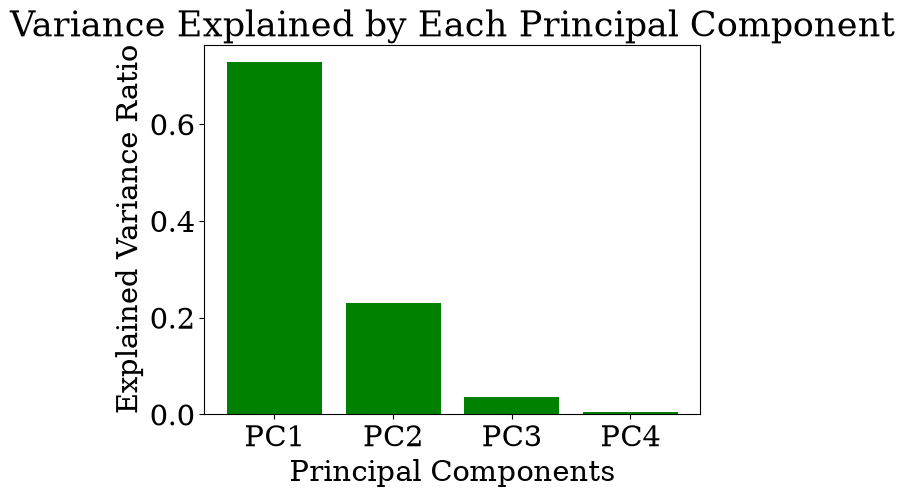

In [60]:
# Convert Polars DataFrame to numpy array, excluding the 'Class' column
X = Iris.drop('Class').to_numpy()
X = torch.tensor(X, dtype=torch.float32)

# Transpose to follow textbook convention: D x N
X = X.T  # Now X is 4 x 150 (D x N)

# Standardize the data (mean=0, std=1)
mean = X.mean(dim=1, keepdim=True)  # Mean per feature (D x 1)
std = X.std(dim=1, keepdim=True)    # Std per feature (D x 1)
X_std = (X - mean) / std            # Standardized data (D x N)

# Perform Singular Value Decomposition (SVD)
Q, L, V = torch.svd(X_std)  # U: D x D, S: min(D, N), V: N x N

# Calculate explained variance ratios
explained_variance_ratio = (L ** 2) / (L ** 2).sum()

print(f"explained variance:{explained_variance_ratio}")

# Determine the number of components for 99% variance
cumulative_variance = torch.cumsum(explained_variance_ratio, dim=0)
n_components = (cumulative_variance >= 0.99).nonzero()[0].item() + 1  # +1 for 1-based index

print(f"Number of components to capture 99% variance: {n_components}")

# Plot the explained variance per component
components = ['PC1', 'PC2', 'PC3', 'PC4']
plt.bar(components, explained_variance_ratio.numpy(), color='green')
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Variance Explained by Each Principal Component')
plt.show()

In [61]:
X_std.shape

torch.Size([4, 150])

In [62]:
Q.shape

torch.Size([4, 4])

In [15]:
L.shape

torch.Size([4])

In [16]:
V.shape

torch.Size([150, 4])

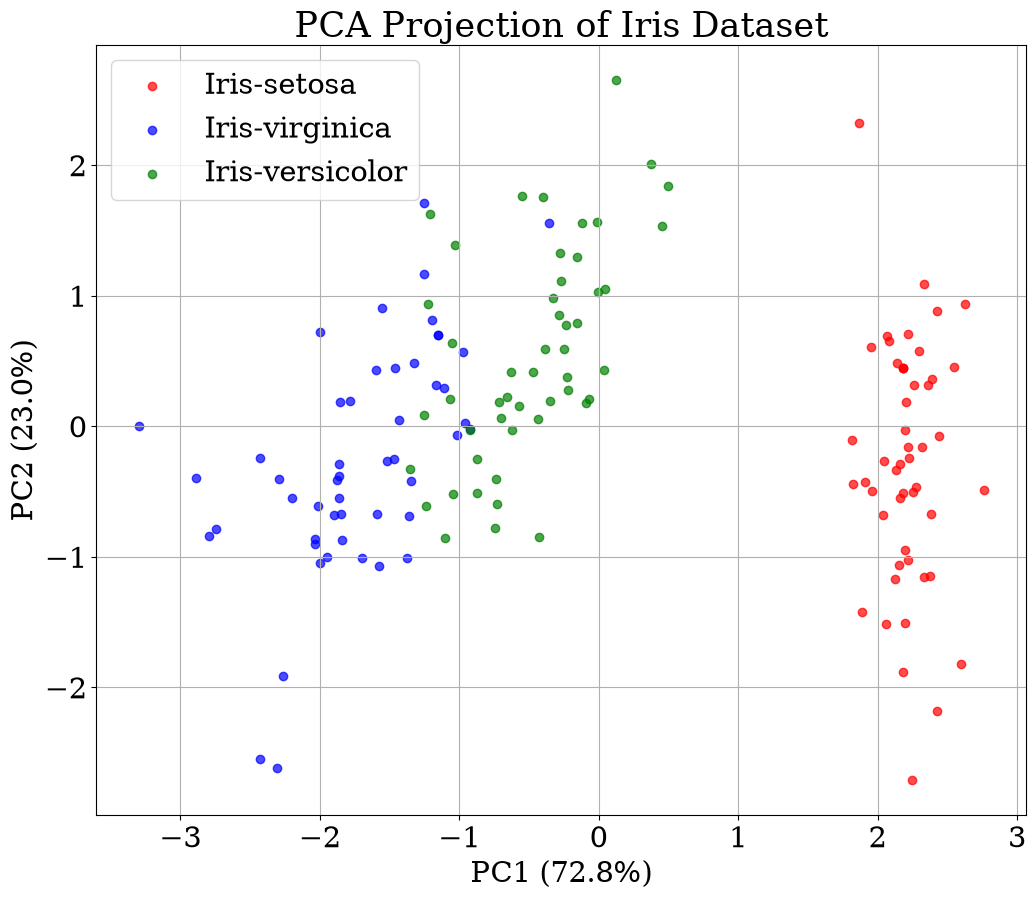

In [63]:

# Project data onto principal components
# Project data onto principal components
scores = (Q.T @ X_std).T  # Transpose to get N x D for easier plotting
pc1 = scores[:, 0]        # First principal component
pc2 = scores[:, 1]        # Second principal component

# Create color mapping for classes
class_names = Iris['Class'].unique()
colors = {'Iris-setosa': 'red', 
          'Iris-versicolor': 'green',
          'Iris-virginica': 'blue'}

# Plot PC1 vs PC2 with class colors
plt.figure(figsize=(12, 10))
for name in class_names:
    mask = Iris['Class'] == name
    plt.scatter(pc1[mask], pc2[mask], 
                c=colors[name], 
                label=name,
                alpha=0.7)

plt.xlabel(f'PC1 ({explained_variance_ratio[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({explained_variance_ratio[1]*100:.1f}%)')
plt.title('PCA Projection of Iris Dataset')
plt.legend()
plt.grid(True)
plt.show()

# 3. PCA using SKlearn

# Extract Features and Class (Labels)

In [64]:
X = Iris[["SepalLength", "SepalWidth", "PetalLength", "PetalWidth"]]
Labels = Iris[["Class"]]

# Scale The Features

In [66]:
# Standardize the features to have mean=0 and variance=1
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)

# Apply PCA

In [67]:
# Apply PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=2)  # We are reducing dimension to 2
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame that will help us in plotting


In [68]:
plot_df = pl.DataFrame({'PC1': X_pca[:, 0], 'PC2': X_pca[:, 1]})
plot_df = pl.concat([plot_df, Labels], how='horizontal')

/tmp/ipykernel_363056/3617086336.py:2: DeprecationWarning: the default behavior of `how='horizontal'` for `concat` is deprecated and will require equal heights in the next breaking release. Use `how='horizontal_extend'` to keep the current behavior.
(Deprecated in version 1.42.1)
  plot_df = pl.concat([plot_df, Labels], how='horizontal')


# Plot

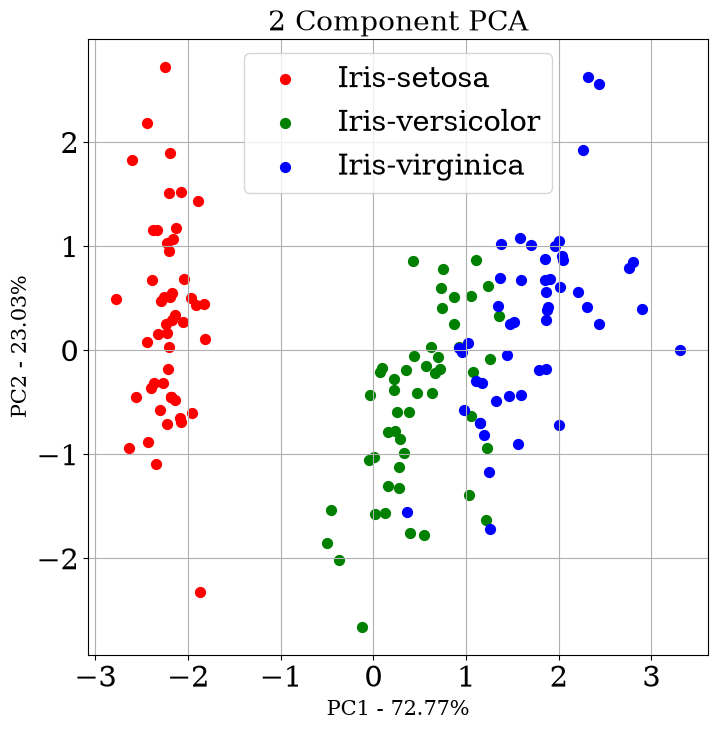

In [69]:
fig = plt.figure(figsize = (8,8))
ax = fig.add_subplot(1,1,1) 
ax.set_xlabel('Principal Component 1', fontsize = 15)
ax.set_ylabel('Principal Component 2', fontsize = 15)
ax.set_title('2 Component PCA', fontsize = 20)

classes = ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
colors = ['r', 'g', 'b']

for target, color in zip(classes, colors):
    indicesToKeep = plot_df['Class'] == target
    subset = plot_df.filter(indicesToKeep)
    ax.scatter(subset['PC1'], subset['PC2'], c = color, s = 50)

ax.legend(classes)
ax.grid()
plt.xlabel('PC1 - {0}%'.format(round(pca.explained_variance_ratio_[0]*100, 2)))
plt.ylabel('PC2 - {0}%'.format(round(pca.explained_variance_ratio_[1]*100, 2)))
plt.show()

# Observation

We see that in latent space, three types of Iris leaves are distinguishable

# 4. PCA on a very high-dimensional Bioinformatics Data

In [72]:
data = pl.read_csv("https://raw.githubusercontent.com/rahulbhadani/Datasets/refs/heads/master/GSE72056/Data1.csv", infer_schema_length=10000)
data = data.drop_nulls()
data.head()

,MMP2,BANK1,TEK,B2M,SNCA,VAT1,ARHGDIB,MFGE8,SRPX,IGSF6,IL2RG,C1QC,KLRF1,IFITM3,CORO1A,HSPB1,SERPING1,HLA.DRA,CST3,CTSB,EFEMP1,PTPRC,COL4A2,LUM,IGFBP6,NID2,TFPI,LCP1,CD22,PPIC,FCER1G,NAPSB,LCK,CD34,FGF7,CALCRL,…,WDFY1,FCHSD2,COX5A,ALDH1A3,CASKIN2,STK3,SLC39A4,ATP5G3,TMEM51,DPYSL3,PDE6A,C10orf10,C12orf44,BNIP3L,FNBP1,PTPRZ1,RELL1,PAPSS2,MIR100HG,WDR61,PTPN22,C22orf28,TMEM55A,TPI1,CA8,CPXM2,RPL13,LIME1,BATF,PDIA5,HGF,DYNC1LI2,AGTRAP,RPL10,PALM,ITGA6,C2
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""cy72.CD45.pos.F08.S932.comb""",0.0,4.2941,0.0,10.182,0.0,0.0,5.0626,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.1573,0.0,0.0,9.1338,0.0,4.7843,0.0,4.2297,0.0,0.0,0.0,0.0,0.0,6.3946,1.3629,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,5.0646,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.9279,0.0,0.0,0.0,3.3795,0.0,1.9859,0.0,0.0,0.0,3.7919,4.9294,0.0,0.0,0.0,0.0,6.6574,0.0,0.0,0.0,0.0,0.0,0.0,8.0289,0.0,0.0,0.0
"""cy84_Primary_CD45_pos_H03_S471…",0.0,0.0,0.0,11.011,0.0,0.0,7.3478,0.0,0.0,0.0,7.0387,0.0,0.0,1.9475,7.693,0.0,0.0,0.68885,0.0,1.5787,0.0,6.3752,0.0,0.0,0.0,0.0,0.0,5.5269,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,1.4265,0.0,0.0,0.0,0.0,0.0,4.3731,0.0,0.0,1.3934,0.0,0.0,0.0,3.7167,0.0,1.082,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.2757,7.1395,0.0,0.0,0.0,0.0,0.0,8.298,0.0,0.0,1.5226
"""Cy59_56""",0.0,0.0,0.0,4.2538,2.6358,3.7239,0.0,3.259,0.0,0.0,0.0,0.0,0.0,4.8649,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,3.5643,0.0,0.0,0.0,0.0,0.0,0.0,2.8858,0.0,0.0,2.2073,0.0,0.0,2.5311,0.0,0.0,2.724,0.0,0.0,0.0,0.0,0.0,0.0,6.0323,0.0,0.0,7.3163,0.0,0.0,0.0,0.0,0.0,0.0,8.5804,0.0,0.0,0.0
"""cy79.p3.CD45.neg.PDL1.neg.B10.…",0.0,0.0,0.0,10.191,4.1745,6.5239,4.3916,7.2226,2.2981,0.0,0.0,0.0,0.0,5.6911,0.0,5.4924,0.0,0.0,6.9529,9.3304,0.0,1.736,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,2.1795,0.0,0.0,0.0,0.0,0.0,4.3934,1.8106,0.0,0.0,0.74502,0.0,0.0,2.917,0.0,0.0,0.78073,0.0,0.0,3.6663,0.0,3.625,0.0,4.7263,0.0,0.0,3.8095,0.0,0.0,0.0,0.0,0.0,4.6172,4.8928,0.0,2.9424,0.0
"""cy94_cd45pos_H11_S191_comb""",0.0,0.0,0.0,10.57,0.0,0.0,6.8512,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.839,0.0,0.0,0.87106,0.0,1.3022,0.0,5.9126,0.0,0.0,0.0,0.0,0.11902,6.0336,0.16864,0.0,0.0,0.0,6.1174,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.4849,0.0,6.8863,0.0,0.31615,0.0,0.64155,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.2259,0.0,0.0,0.0,0.0,0.0,0.0,8.0379,0.0,0.0,0.0


In [73]:
# Remove the first column which is row names
data = data.select(data.columns[1:])
data.head()

MMP2,BANK1,TEK,B2M,SNCA,VAT1,ARHGDIB,MFGE8,SRPX,IGSF6,IL2RG,C1QC,KLRF1,IFITM3,CORO1A,HSPB1,SERPING1,HLA.DRA,CST3,CTSB,EFEMP1,PTPRC,COL4A2,LUM,IGFBP6,NID2,TFPI,LCP1,CD22,PPIC,FCER1G,NAPSB,LCK,CD34,FGF7,CALCRL,THBS2,…,WDFY1,FCHSD2,COX5A,ALDH1A3,CASKIN2,STK3,SLC39A4,ATP5G3,TMEM51,DPYSL3,PDE6A,C10orf10,C12orf44,BNIP3L,FNBP1,PTPRZ1,RELL1,PAPSS2,MIR100HG,WDR61,PTPN22,C22orf28,TMEM55A,TPI1,CA8,CPXM2,RPL13,LIME1,BATF,PDIA5,HGF,DYNC1LI2,AGTRAP,RPL10,PALM,ITGA6,C2
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.0,4.2941,0.0,10.182,0.0,0.0,5.0626,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.1573,0.0,0.0,9.1338,0.0,4.7843,0.0,4.2297,0.0,0.0,0.0,0.0,0.0,6.3946,1.3629,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,5.0646,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.9279,0.0,0.0,0.0,3.3795,0.0,1.9859,0.0,0.0,0.0,3.7919,4.9294,0.0,0.0,0.0,0.0,6.6574,0.0,0.0,0.0,0.0,0.0,0.0,8.0289,0.0,0.0,0.0
0.0,0.0,0.0,11.011,0.0,0.0,7.3478,0.0,0.0,0.0,7.0387,0.0,0.0,1.9475,7.693,0.0,0.0,0.68885,0.0,1.5787,0.0,6.3752,0.0,0.0,0.0,0.0,0.0,5.5269,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,1.4265,0.0,0.0,0.0,0.0,0.0,4.3731,0.0,0.0,1.3934,0.0,0.0,0.0,3.7167,0.0,1.082,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.2757,7.1395,0.0,0.0,0.0,0.0,0.0,8.298,0.0,0.0,1.5226
0.0,0.0,0.0,4.2538,2.6358,3.7239,0.0,3.259,0.0,0.0,0.0,0.0,0.0,4.8649,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.2563,…,3.5643,0.0,0.0,0.0,0.0,0.0,0.0,2.8858,0.0,0.0,2.2073,0.0,0.0,2.5311,0.0,0.0,2.724,0.0,0.0,0.0,0.0,0.0,0.0,6.0323,0.0,0.0,7.3163,0.0,0.0,0.0,0.0,0.0,0.0,8.5804,0.0,0.0,0.0
0.0,0.0,0.0,10.191,4.1745,6.5239,4.3916,7.2226,2.2981,0.0,0.0,0.0,0.0,5.6911,0.0,5.4924,0.0,0.0,6.9529,9.3304,0.0,1.736,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,2.1795,0.0,0.0,0.0,0.0,0.0,4.3934,1.8106,0.0,0.0,0.74502,0.0,0.0,2.917,0.0,0.0,0.78073,0.0,0.0,3.6663,0.0,3.625,0.0,4.7263,0.0,0.0,3.8095,0.0,0.0,0.0,0.0,0.0,4.6172,4.8928,0.0,2.9424,0.0
0.0,0.0,0.0,10.57,0.0,0.0,6.8512,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.839,0.0,0.0,0.87106,0.0,1.3022,0.0,5.9126,0.0,0.0,0.0,0.0,0.11902,6.0336,0.16864,0.0,0.0,0.0,6.1174,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.4849,0.0,6.8863,0.0,0.31615,0.0,0.64155,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.2259,0.0,0.0,0.0,0.0,0.0,0.0,8.0379,0.0,0.0,0.0


In [74]:
data.shape

(3384, 2000)

So we have 3384 samples and 2000 features

# Apply PCA with two components

In [75]:

pca_2 = PCA(n_components=2)
data_2d = pca_2.fit_transform(data)

# Plot two components

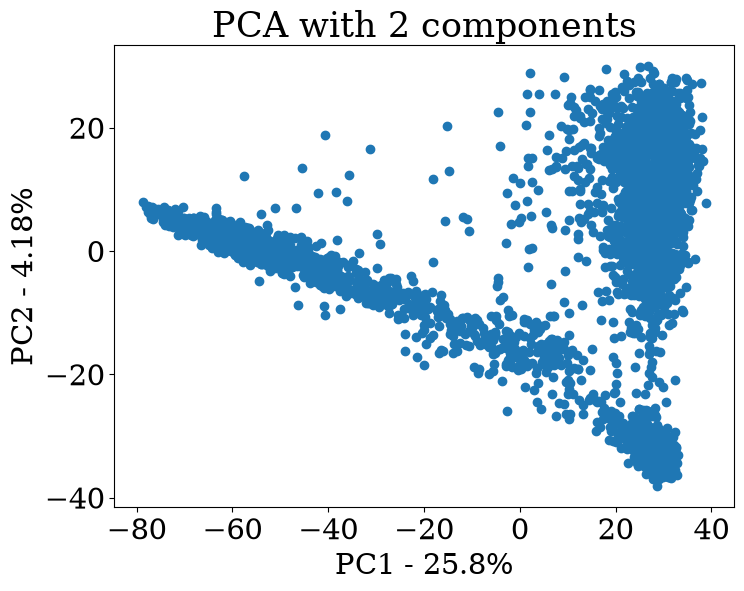

In [76]:
# Plot 2D
plt.figure(figsize=(8,6))
plt.scatter(data_2d[:,0], data_2d[:,1])
plt.title('PCA with 2 components')
plt.xlabel('PC1 - {0}%'.format(round(pca_2.explained_variance_ratio_[0]*100, 2)))
plt.ylabel('PC2 - {0}%'.format(round(pca_2.explained_variance_ratio_[1]*100, 2)))
plt.show()


In [77]:
pca_2.explained_variance_ratio_

array([0.25799759, 0.04175993])

In [78]:
df_2d = pl.DataFrame({'PC1': data_2d[:, 0], 'PC2': data_2d[:, 1]})
df_2d

PC1,PC2
f64,f64
23.504171,-26.750152
29.982999,1.233877
-5.584546,-14.479312
-64.487984,2.014553
29.389704,-7.38203
…,…
29.134932,-21.260951
24.977464,1.12747
20.066902,11.102046


# Apply PCA with three components

In [79]:
pca_3 = PCA(n_components=3)
data_3d = pca_3.fit_transform(data)

# Plot three components

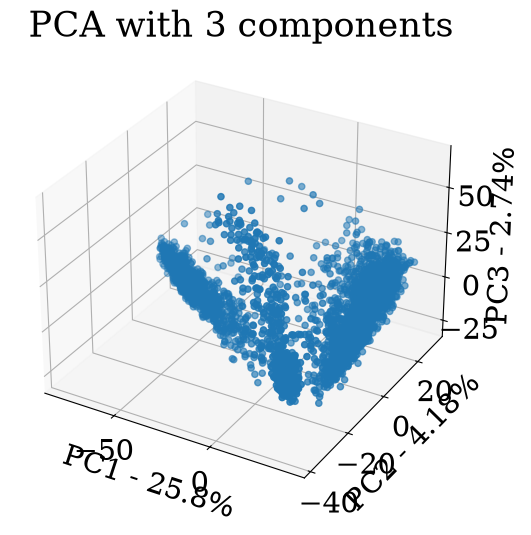

In [80]:
# Plot 3D
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(data_3d[:,0], data_3d[:,1], data_3d[:,2])
ax.set_title('PCA with 3 components')
ax.set_xlabel('PC1 - {0}%'.format(round(pca_3.explained_variance_ratio_[0]*100, 2)))
ax.set_ylabel('PC2 - {0}%'.format(round(pca_3.explained_variance_ratio_[1]*100, 2)))
ax.set_zlabel('PC3 - {0}%'.format(round(pca_3.explained_variance_ratio_[2]*100, 2)))
plt.show()

# Interactive 3D Plot


In [81]:
import plotly.express as px

# Create a DataFrame for the 3D PCA result
df_3d = pl.DataFrame({'PC1': data_3d[:, 0], 'PC2': data_3d[:, 1], 'PC3': data_3d[:, 2]})

# Create the 3D plot
fig = px.scatter_3d(df_3d, x='PC1', y='PC2', z='PC3')

# Customize the axes labels
fig.update_layout(scene=dict(
                    xaxis=dict(range=[df_3d['PC1'].min(), df_3d['PC1'].max()]),
                    yaxis=dict(range=[df_3d['PC2'].min(), df_3d['PC2'].max()]),
                    zaxis=dict(range=[df_3d['PC3'].min(), df_3d['PC3'].max()]),
                    aspectmode='cube',
                    xaxis_title='PC1 - {0}%'.format(round(pca_3.explained_variance_ratio_[0]*100, 2)),
                    yaxis_title='PC2 - {0}%'.format(round(pca_3.explained_variance_ratio_[1]*100, 2)),
                    zaxis_title='PC3 - {0}%'.format(round(pca_3.explained_variance_ratio_[2]*100, 2))
))

fig.show()

In [82]:
df_3d

PC1,PC2,PC3
f64,f64,f64
23.504171,-26.750153,2.933376
29.982999,1.233877,-13.096264
-5.584546,-14.479312,-25.056059
-64.487984,2.014553,-3.124316
29.389704,-7.382029,-15.936044
…,…,…
29.134932,-21.26095,9.140184
24.977464,1.127471,-12.628149
20.066902,11.102045,6.931614


# PCA By hand

In [83]:
import math
import torch
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float64) 
torch.set_printoptions(precision=4, sci_mode=False)

In [84]:
# Four samples, two features. Rows are samples, so X is N x D.
# The SVD frames on the slides use the transpose, D x N.
X = torch.tensor([[-13.0, -2.0],
                  [  1.0, -4.0],
                  [  9.0,  2.0],
                  [ 11.0, 16.0]])
N, D = X.shape
print(f"N = {N} samples, D = {D} features")

N = 4 samples, D = 2 features


In [85]:
mu = X.sum(dim=0) / N   # column means
Xc = X - mu             # broadcasting subtracts mu from the rows

print("mu =", mu)
print("centered data:\n", Xc)
print("column means after centering:", Xc.mean(dim=0))

mu = tensor([2., 3.])
centered data:
 tensor([[-15.,  -5.],
        [ -1.,  -7.],
        [  7.,  -1.],
        [  9.,  13.]])
column means after centering: tensor([0., 0.])


## covariance calculation

In [86]:
Sigma_loop = torch.zeros(D, D)
for i in range(N):
    Sigma_loop += torch.outer(Xc[i], Xc[i])
Sigma_loop /= N

# The same matrix as one product
Sigma = Xc.T @ Xc / N
assert torch.allclose(Sigma, Sigma_loop)

trace = Sigma[0, 0] + Sigma[1, 1]
det = Sigma[0, 0] * Sigma[1, 1] - Sigma[0, 1] * Sigma[1, 0]
corr = Sigma[0, 1] / torch.sqrt(Sigma[0, 0] * Sigma[1, 1])

print("Sigma =\n", Sigma)
print(f"trace = {trace:.0f}, det = {det:.0f}, correlation = {corr:.2f}")

Sigma =
 tensor([[89., 48.],
        [48., 61.]])
trace = 150, det = 3125, correlation = 0.65


# eigenvalues from characteristics polynomial

In [87]:
# det(Sigma - lam I) = lam^2 - trace * lam + det = 0, solved with the quadratic formula
disc = torch.sqrt(trace**2 - 4 * det)
lam1 = (trace + disc) / 2
lam2 = (trace - disc) / 2

def eigvec_2x2(S, lam):
    # Row 2 of (S - lam I) b = 0 reads S[1,0] b[0] + (S[1,1] - lam) b[1] = 0,
    # so b is parallel to (lam - S[1,1], S[1,0]). This shortcut is for 2 x 2 only.
    v = torch.stack([lam - S[1, 1], S[1, 0]])
    return v / v.norm()

b1 = eigvec_2x2(Sigma, lam1)
b2 = eigvec_2x2(Sigma, lam2)

print(f"lambda1 = {lam1:.1f}, lambda2 = {lam2:.1f}")
print("b1 =", b1, "  b2 =", b2)

# The checks from the slide
print("Sigma b1 - lambda1 b1 =", Sigma @ b1 - lam1 * b1)
print(f"lambda1 + lambda2 = {lam1 + lam2:.0f}, lambda1 * lambda2 = {lam1 * lam2:.0f}")
print(f"b1 . b2 = {b1 @ b2:.4f}")

lambda1 = 125.0, lambda2 = 25.0
b1 = tensor([0.8000, 0.6000])   b2 = tensor([-0.6000,  0.8000])
Sigma b1 - lambda1 b1 = tensor([0., 0.])
lambda1 + lambda2 = 150, lambda1 * lambda2 = 3125
b1 . b2 = 0.0000


In [41]:
def fix_sign(B):
    # An eigenvector is fixed only up to sign. Flip a column when its
    # largest-magnitude entry is negative
    rows = B.abs().argmax(dim=0)
    signs = torch.sign(B[rows, torch.arange(B.shape[1])])
    return B * signs

def power_iteration(S, n_iter=1000, tol=1e-12, seed=0):
    g = torch.Generator().manual_seed(seed)
    b = torch.randn(S.shape[0], generator=g).to(S)   # match the dtype and device of S
    b = b / b.norm()
    for step in range(1, n_iter + 1):
        Sb = S @ b
        if Sb.norm() == 0:        # S b = 0, so b is an eigenvector with eigenvalue 0
            break
        b_new = Sb / Sb.norm()
        converged = (b_new - b).norm() < tol
        b = b_new
        if converged:
            break
    lam = b @ S @ b               # Rayleigh quotient b^T S b gives the eigenvalue
    return lam, b, step

def top_k_eig(S, k, verbose=False):
    S = S.clone()
    lams, vecs = [], []
    for j in range(k):
        lam, b, steps = power_iteration(S)
        if verbose:
            print(f"component {j + 1}: lambda = {lam:.4f} after {steps} iterations")
        lams.append(lam)
        vecs.append(b)
        S = S - lam * torch.outer(b, b)   # Hotelling's deflation removes the direction just found
    return torch.stack(lams), fix_sign(torch.stack(vecs, dim=1))

lam_pi, U_pi = top_k_eig(Sigma, k=D, verbose=True)
print("eigenvectors (columns):\n", U_pi)

component 1: lambda = 125.0000 after 19 iterations
component 2: lambda = 25.0000 after 2 iterations
eigenvectors (columns):
 tensor([[ 0.8000, -0.6000],
        [ 0.6000,  0.8000]])


## Maximize projected variance

V1 = 125.000000, V2 = 25.000000
directions (columns):
 tensor([[ 0.8000, -0.6000],
        [ 0.6000,  0.8000]])
Sigma b1 - V1 b1 = tensor([-0.0000,  0.0000])


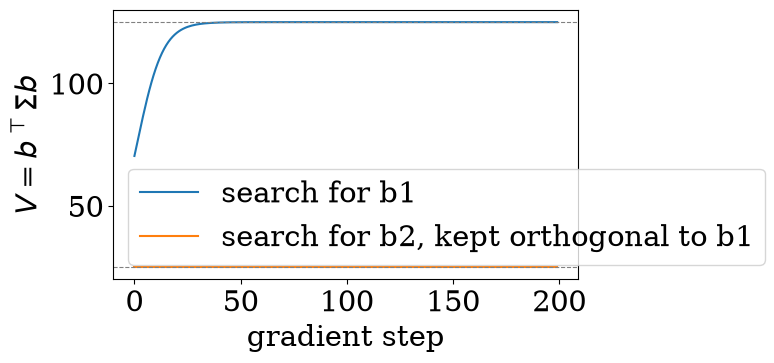

In [88]:
def unit_direction(w, previous):
    # Remove the parts of w along earlier components, then scale to length 1.
    # This enforces b^T b = 1 and b^T b_k = 0 without a Lagrange multiplier.
    for u in previous:
        w = w - (u @ w) * u
    return w / w.norm()

def max_variance_direction(S, previous=(), steps=200, lr=1e-3, seed=0):
    g = torch.Generator().manual_seed(seed)
    w = torch.randn(S.shape[0], generator=g).to(S).requires_grad_()
    opt = torch.optim.SGD([w], lr=lr)
    history = []
    for _ in range(steps):
        b = unit_direction(w, previous)
        V = b @ S @ b              # variance of the data projected onto b
        opt.zero_grad()
        (-V).backward()            # minimizing -V is gradient ascent on V
        opt.step()
        history.append(V.item())
    with torch.no_grad():
        b = unit_direction(w, previous)
        V = b @ S @ b
    return V, b, history

V1, g1, hist1 = max_variance_direction(Sigma)
V2, g2, hist2 = max_variance_direction(Sigma, previous=[g1])
U_ag = fix_sign(torch.stack([g1, g2], dim=1))

print(f"V1 = {V1:.6f}, V2 = {V2:.6f}")
print("directions (columns):\n", U_ag)
print("Sigma b1 - V1 b1 =", Sigma @ g1 - V1 * g1)   # zero at the optimum, as the Lagrange condition says

plt.figure(figsize=(6, 3.5))
plt.plot(hist1, label="search for b1")
plt.plot(hist2, label="search for b2, kept orthogonal to b1")
plt.axhline(125, ls="--", c="gray", lw=0.8)
plt.axhline(25, ls="--", c="gray", lw=0.8)
plt.xlabel("gradient step")
plt.ylabel(r"$V = b^\top \Sigma b$")
plt.legend()
plt.show()

In [89]:
lam = torch.stack([lam1, lam2])
U = torch.stack([b1, b2], dim=1)       # D x D, columns are b1 and b2

print("power iteration matches:", torch.allclose(lam_pi, lam), torch.allclose(U_pi, U))
print("autograd matches:       ",
      torch.allclose(torch.stack([V1, V2]), lam, atol=1e-6), torch.allclose(U_ag, U, atol=1e-6))

ratio = lam / lam.sum()
print("explained variance ratio:", ratio)
print("cumulative:", torch.cumsum(ratio, dim=0))

power iteration matches: True True
autograd matches:        True True
explained variance ratio: tensor([0.8333, 0.1667])
cumulative: tensor([0.8333, 1.0000])


# project onto PCA1

In [90]:
M = 1
B = U[:, :M]           # D x M, keeps b1 only
Z = Xc @ B             # N x M, z_i = b1^T (x_i - mu)

print("z =", Z.squeeze())
print(f"variance of z = {(Z**2).mean():.0f}  (lambda1 = {lam1:.0f})")

z = tensor([-15.0000,  -5.0000,   5.0000,  15.0000])
variance of z = 125  (lambda1 = 125)


## reconstruction

In [91]:
X_hat = mu + Z @ B.T          # x_hat_i = mu + B z_i
R = X - X_hat                  # residuals
sq = (R**2).sum(dim=1)         # squared residual norms

def pair(v):
    return f"({round(v[0].item())}, {round(v[1].item())})"

print(f"{'i':>2} {'z_i':>5} {'x_hat_i':>10} {'x_i - x_hat_i':>14} {'||.||^2':>8}")
for i in range(N):
    print(f"{i + 1:>2} {Z[i, 0]:>5.0f} {pair(X_hat[i]):>10} {pair(R[i]):>14} {sq[i]:>8.0f}")

print(f"\nError = {sq.mean():.0f}  (lambda2 = {lam2:.0f})")
print("residuals . b1 =", R @ b1)   # zero, so the residuals lie along +/- b2

 i   z_i    x_hat_i  x_i - x_hat_i  ||.||^2
 1   -15  (-10, -6)        (-3, 4)       25
 2    -5    (-2, 0)        (3, -4)       25
 3     5     (6, 6)        (3, -4)       25
 4    15   (14, 12)        (-3, 4)       25

Error = 25  (lambda2 = 25)
residuals . b1 = tensor([-0.0000,  0.0000, -0.0000, -0.0000])


## Error vs M

In [92]:
for m in range(D + 1):
    Bm = U[:, :m]
    X_hat_m = mu + (Xc @ Bm) @ Bm.T
    err = ((X - X_hat_m)**2).sum(dim=1).mean()
    print(f"M = {m}: error = {err:6.1f},  sum of discarded eigenvalues = {lam[m:].sum():6.1f}")

M = 0: error =  150.0,  sum of discarded eigenvalues =  150.0
M = 1: error =   25.0,  sum of discarded eigenvalues =   25.0
M = 2: error =    0.0,  sum of discarded eigenvalues =    0.0


# check with scikit implementation

In [93]:
# eigh returns eigenvalues in ascending order, so flip to largest first
evals, evecs = torch.linalg.eigh(Sigma)
evals, evecs = evals.flip(0), fix_sign(evecs.flip(1))

# Xc is the transpose of the slides' X, so Xc = V Gamma^T Q^T.
# torch returns (V, gamma, Q^T). The columns of Q are the principal directions.
V_svd, gamma, QT = torch.linalg.svd(Xc, full_matrices=False)
lam_svd = gamma**2 / N
U_svd = fix_sign(QT.T)

print("eigh:", evals, torch.allclose(evals, lam), torch.allclose(evecs, U))
print("svd: ", lam_svd, torch.allclose(lam_svd, lam), torch.allclose(U_svd, U))

eigh: tensor([125.0000,  25.0000]) True True
svd:  tensor([125.0000,  25.0000]) True True


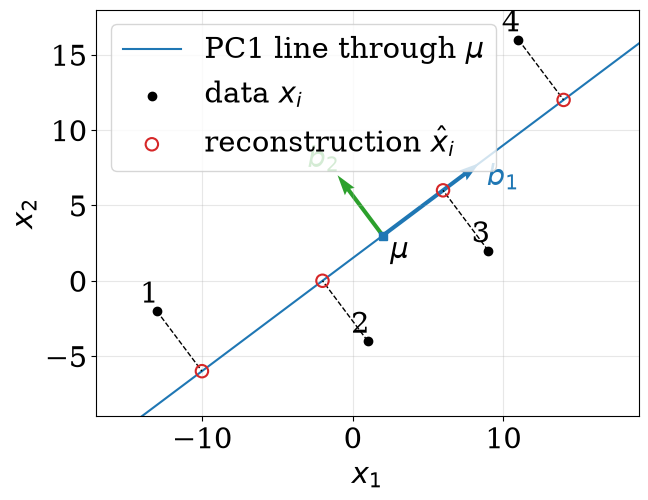

In [94]:
Xn, Xh, m0, u1, u2 = (t.numpy() for t in (X, X_hat, mu, b1, b2))

fig, ax = plt.subplots(figsize=(7, 5.5))
ends = [m0 - 25 * u1, m0 + 25 * u1]
ax.plot([ends[0][0], ends[1][0]], [ends[0][1], ends[1][1]], c="tab:blue", lw=1.5,
        label=r"PC1 line through $\mu$")
ax.scatter(Xn[:, 0], Xn[:, 1], c="black", zorder=3, label=r"data $x_i$")
ax.scatter(Xh[:, 0], Xh[:, 1], facecolors="none", edgecolors="tab:red", s=80, lw=1.5,
           zorder=3, label=r"reconstruction $\hat{x}_i$")
for i in range(N):
    ax.plot([Xn[i, 0], Xh[i, 0]], [Xn[i, 1], Xh[i, 1]], "k--", lw=1)
    ax.annotate(str(i + 1), Xn[i], textcoords="offset points", xytext=(-12, 6))
ax.quiver(m0[0], m0[1], 8 * u1[0], 8 * u1[1], angles="xy", scale_units="xy", scale=1, color="tab:blue")
ax.quiver(m0[0], m0[1], 5 * u2[0], 5 * u2[1], angles="xy", scale_units="xy", scale=1, color="tab:green")
ax.text(m0[0] + 8 * u1[0] + 0.5, m0[1] + 8 * u1[1] - 1.5, r"$b_1$", color="tab:blue")
ax.text(m0[0] + 5 * u2[0] - 2.0, m0[1] + 5 * u2[1] + 0.5, r"$b_2$", color="tab:green")
ax.plot(m0[0], m0[1], "s", c="tab:blue")
ax.text(m0[0] + 0.5, m0[1] - 1.5, r"$\mu$")
ax.set_aspect("equal")
ax.set_xlim(-17, 19)
ax.set_ylim(-9, 18)
ax.grid(alpha=0.3)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.legend(loc="upper left")
plt.show()